# Iris Project Setup and Backend/Frontend Creation

This notebook adds the project directories and application files while preserving the existing Iris model.

## 1. Create Project Directories

Use `pathlib` to locate the project and create `backend` and `frontend` without changing `notebooks`.

In [ ]:
from pathlib import Path

project_root = Path.cwd()
if project_root.name != "iris-classification":
    project_root = next((p for p in project_root.rglob("iris-classification") if p.is_dir()), project_root)

(project_root / "backend").mkdir(parents=True, exist_ok=True)
(project_root / "frontend").mkdir(parents=True, exist_ok=True)

print(project_root)
print("Backend:", project_root / "backend")
print("Frontend:", project_root / "frontend")

## 2. Copy Existing Iris Model

Search the project for the original model and copy it to `backend/iris_model.pkl`. The original copy is preserved.

In [ ]:
import shutil

original_models = list(project_root.rglob("iris_model.pkl"))
if not original_models:
    raise FileNotFoundError("No original iris_model.pkl file was found")

original_model = original_models[0]
backend_model = project_root / "backend" / "iris_model.pkl"
shutil.copy2(original_model, backend_model)

print("Original:", original_model)
print("Copied:", backend_model)
print("Original exists:", original_model.exists())

In [1]:
# Import the necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

# Load the Iris dataset from Scikit-learn

iris = load_iris(as_frame=True)

# Convert the dataset into a Pandas DataFrame

df = iris.frame

# Display the first five rows

df.head()

Matplotlib is building the font cache; this may take a moment.


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [2]:
# Display the number of rows and columns

print("Dataset Shape:", df.shape)

# Display all column names

print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information

print("\nDataset Information:")
df.info()

Dataset Shape: (150, 5)

Column Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [3]:
# Display the target classes

print("Target Names:")
print(iris.target_names)

# Count the observations in each class

print("\nClass Distribution:")
print(df["target"].value_counts().sort_index())

Target Names:
['setosa' 'versicolor' 'virginica']

Class Distribution:
target
0    50
1    50
2    50
Name: count, dtype: int64


In [4]:
# Replace numerical target values with species names

df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)

# Remove the original numerical target column

df.drop(columns=["target"], inplace=True)

# Display the first five rows

df.head()

C:\Users\Paul Boison\AppData\Local\Temp\ipykernel_12392\2279819228.py:9: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["target"], inplace=True)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [5]:
# Check missing values in each column

print("Missing Values:")
print(df.isnull().sum())

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


In [6]:
# Count duplicate records

print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 1


In [7]:
# Generate descriptive statistics

df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


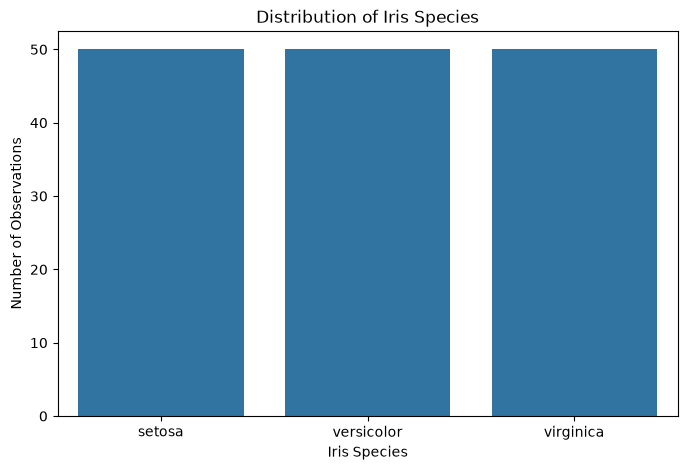

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Species")
plt.xlabel("Iris Species")
plt.ylabel("Number of Observations")

plt.show()

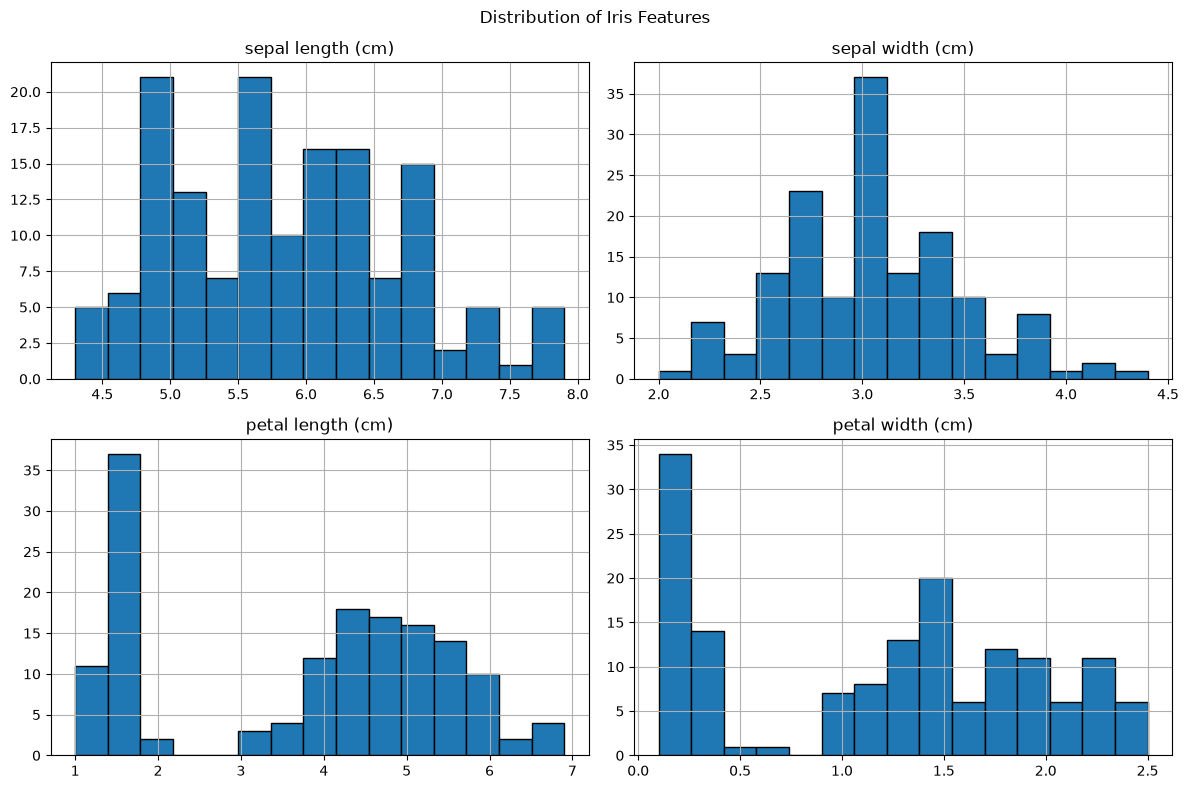

In [9]:
df.iloc[:, :4].hist(
    figsize=(12, 8),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Iris Features")
plt.tight_layout()
plt.show()

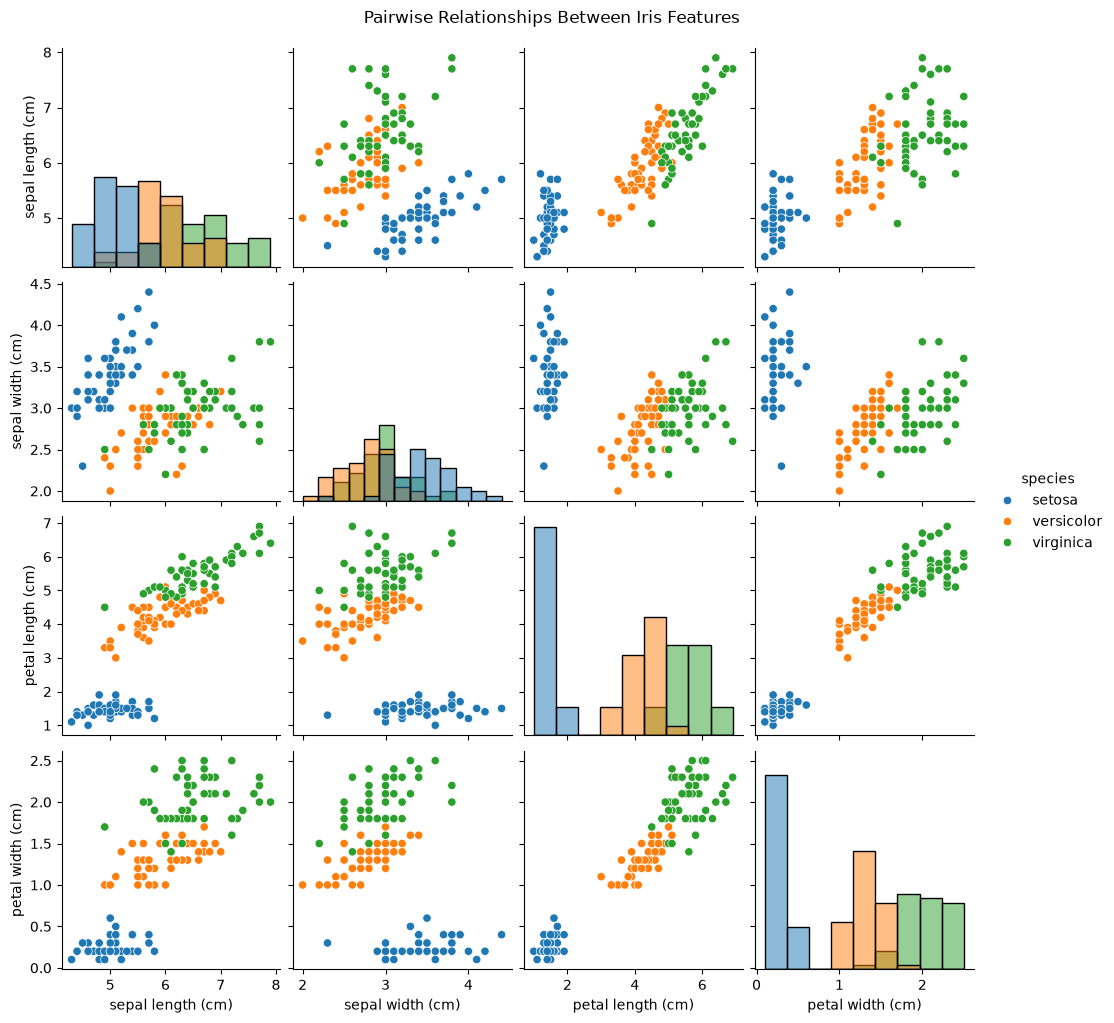

In [10]:
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle(
    "Pairwise Relationships Between Iris Features",
    y=1.02
)

plt.show()

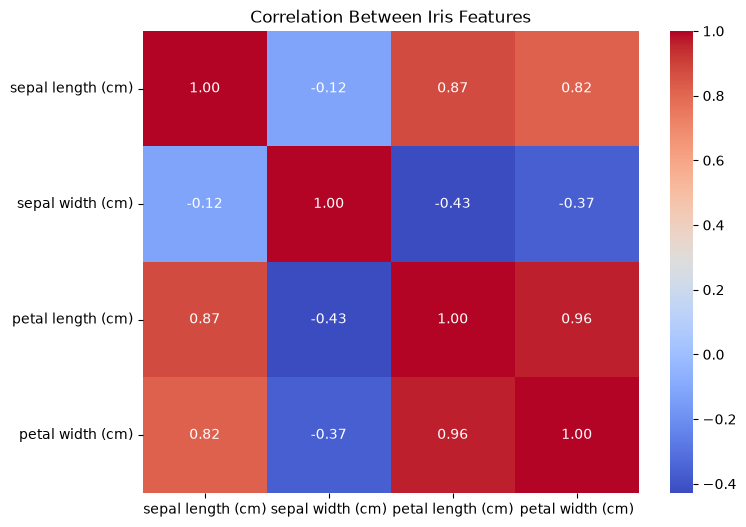

In [11]:
plt.figure(figsize=(8, 6))

correlation = df.iloc[:, :4].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Iris Features")
plt.show()

In [12]:
# Separate input features (X) and target variable (y)

X = df.drop("species", axis=1)
y = df["species"]

# Display the features
print("Input Features:")
print(X.head())

# Display the target
print("\nTarget Variable:")
print(y.head())

Input Features:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target Variable:
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: str


In [13]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (120, 4)
Testing Features: (30, 4)
Training Target: (120,)
Testing Target: (30,)


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Define the classification models

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "K-Nearest Neighbours": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

print("Four classification models have been defined successfully.")

Four classification models have been defined successfully.


In [15]:
# Train all classification models

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
K-Nearest Neighbours trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.


In [16]:
# Generate predictions from each model

predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    print(f"{name} predictions completed.")

Logistic Regression predictions completed.
K-Nearest Neighbours predictions completed.
Decision Tree predictions completed.
Random Forest predictions completed.


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Store evaluation results

results = []

for name, y_pred in predictions.items():

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    weighted_precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    weighted_recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    weighted_f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1-Score": f1,
        "Weighted Precision": weighted_precision,
        "Weighted Recall": weighted_recall,
        "Weighted F1-Score": weighted_f1
    })

# Display results in a DataFrame

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

results_df.round(4)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score,Weighted Precision,Weighted Recall,Weighted F1-Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333
1,K-Nearest Neighbours,0.9333,0.9444,0.9333,0.9327,0.9444,0.9333,0.9327
2,Decision Tree,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333
3,Random Forest,0.9000,0.9024,0.9000,0.8997,0.9024,0.9000,0.8997


In [18]:
from sklearn.metrics import classification_report

for name, y_pred in predictions.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=iris.target_names,
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


K-Nearest Neighbours
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30


Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica     

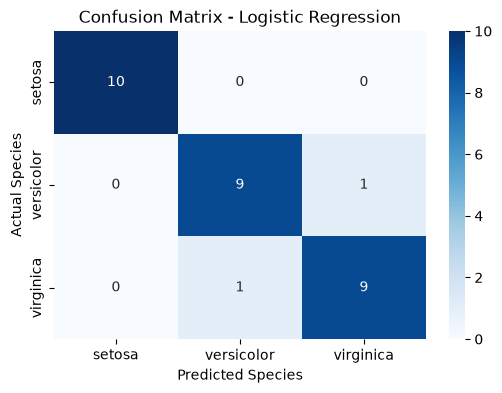

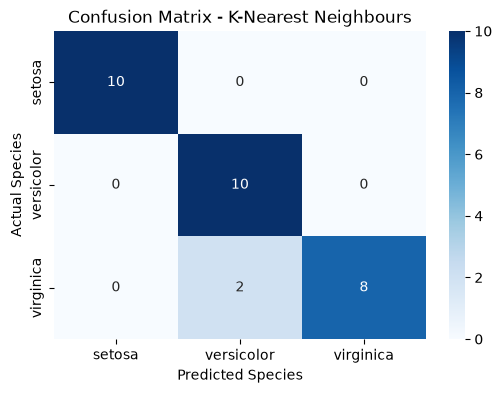

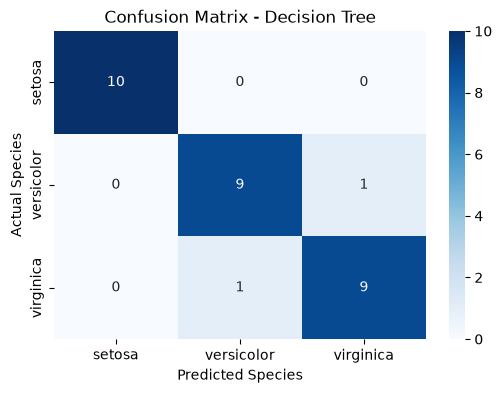

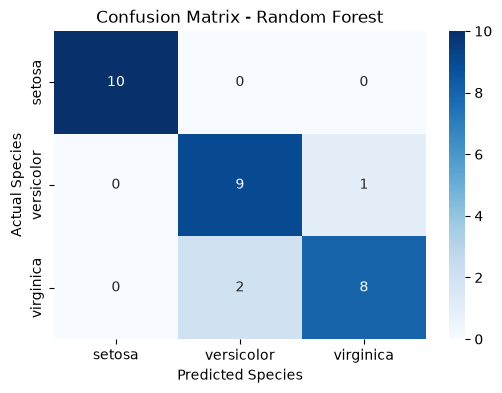

In [19]:
from sklearn.metrics import confusion_matrix

for name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=iris.target_names
    )

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=iris.target_names,
        yticklabels=iris.target_names
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Species")
    plt.ylabel("Actual Species")

    plt.show()

In [20]:
from sklearn.metrics import roc_auc_score

roc_results = []

for name, model in models.items():

    # Get predicted probabilities
    y_prob = model.predict_proba(X_test)

    # Calculate multiclass ROC-AUC
    auc = roc_auc_score(
        y_test,
        y_prob,
        multi_class="ovr",
        labels=model.classes_
    )

    roc_results.append({
        "Model": name,
        "ROC-AUC": auc
    })

roc_df = pd.DataFrame(roc_results)

roc_df.round(4)

,Model,ROC-AUC
0,Logistic Regression,0.9967
1,K-Nearest Neighbours,0.9933
2,Decision Tree,0.9500
3,Random Forest,0.9867


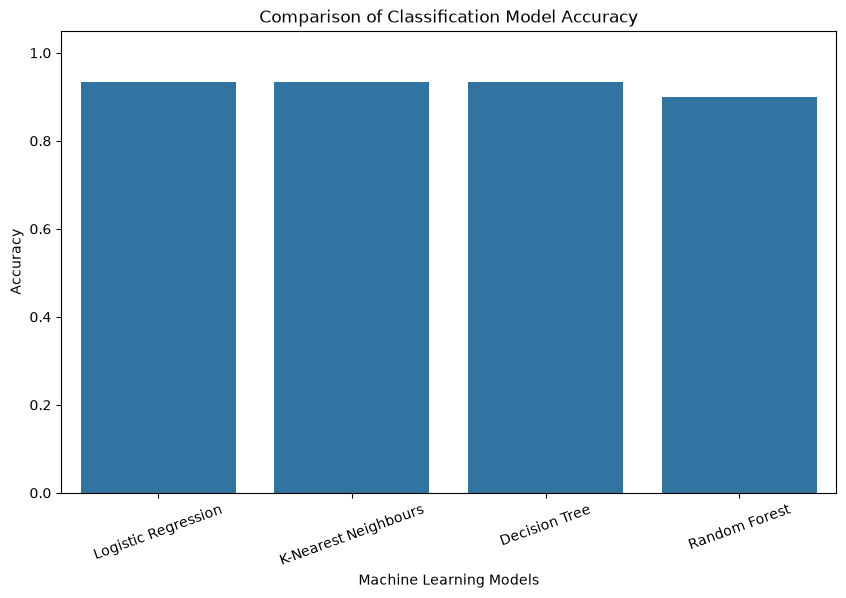

In [21]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Comparison of Classification Model Accuracy")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")

plt.ylim(0, 1.05)
plt.xticks(rotation=20)

plt.show()
